# Définir l'activation « haute » et « basse »

**Question** : chaque participant note son activation de 1 à 9 après chaque vidéo, mais chacun utilise
l'échelle à sa façon. Comment décider, pour chaque personne, quelles vidéos sont à activation
« haute » et lesquelles à activation « basse », de façon comparable entre participants ?

**Démarche** : (1) regarder comment l'échelle est utilisée ; (2) comparer quatre définitions avec des
critères objectifs ; (3) retenir une définition commune à toute l'équipe, codée dans
[`arousal_split.py`](arousal_split.py).

Données : `labels_train.csv` uniquement (notes post-vidéo des participants d'entraînement).

In [1]:
import os
os.environ.setdefault("HABS_DATA", r"C:\Users\ehren\habs-data")   # à adapter sur ta machine

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arousal_split import *

plt.rcParams["figure.dpi"] = 90
lab = load_ratings()
print(f"{len(lab)} vidéos notées, {lab.participant_id.nunique()} participants")

27221 vidéos notées, 317 participants


## 1. Comment l'échelle est-elle utilisée ?

### Deux façons de noter selon la cohorte
La cohorte 1 note avec des **nombres entiers** (1, 2, …, 9) ; les cohortes 2 à 5 avec un **curseur**
(valeurs continues comme 4,06). Toute définition doit marcher dans les deux cas.

         participants  notes_entieres  videos_par_personne
cohorte                                                   
1                 106            1.00                 83.0
2                 115            0.06                104.0
3                  30            0.11                103.0
4                  52            0.09                101.5
5                  14            0.16                 23.0


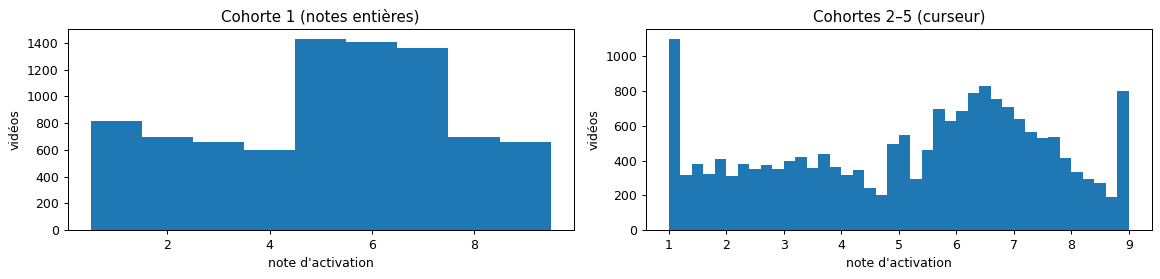

In [2]:
u = scale_usage(lab)
print(u.groupby("cohorte").agg(participants=("n_videos", "size"), notes_entieres=("notes_entieres", "mean"),
                               videos_par_personne=("n_videos", "median")).round(2))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.2))
for coh, ax, title in [(1, axs[0], "Cohorte 1 (notes entières)"), (None, axs[1], "Cohortes 2–5 (curseur)")]:
    x = lab.rating_arousal[lab.cohort == 1] if coh == 1 else lab.rating_arousal[lab.cohort != 1]
    ax.hist(x, bins=np.arange(0.5, 9.6, 1) if coh == 1 else 40, color="C0")
    ax.set_title(title); ax.set_xlabel("note d'activation"); ax.set_ylabel("vidéos")
plt.tight_layout(); plt.show()

### Chacun note à sa façon
Moyenne et dispersion (écart-type) des notes de chaque participant. La plupart utilisent une grande
partie de l'échelle ; quelques-uns notent presque toujours pareil.

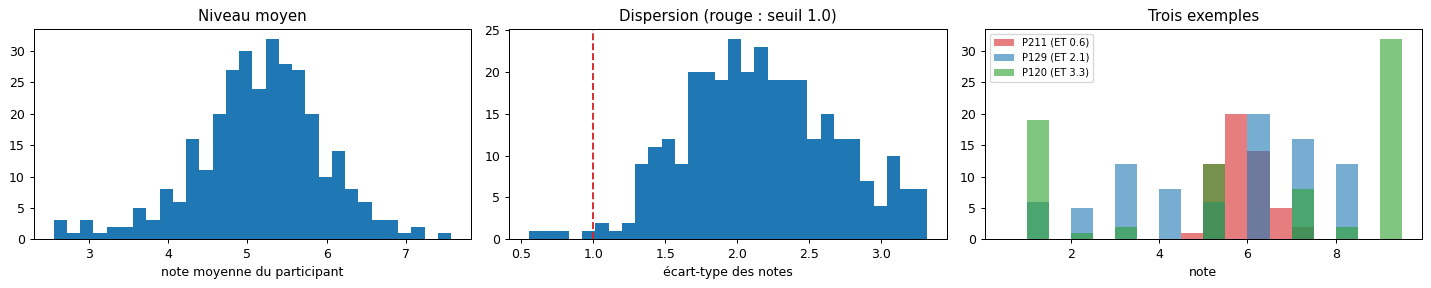

Écart-type < 1.0 : 4 participants ; < 1,5 : 31
Note moyenne : de 2.6 à 7.6 selon les participants


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.3))
axs[0].hist(u.moyenne, bins=30, color="C0"); axs[0].set_xlabel("note moyenne du participant"); axs[0].set_title("Niveau moyen")
axs[1].hist(u.ecart_type, bins=30, color="C0"); axs[1].axvline(MIN_SD, color="C3", ls="--")
axs[1].set_xlabel("écart-type des notes"); axs[1].set_title(f"Dispersion (rouge : seuil {MIN_SD})")
ex = [u.ecart_type.idxmin(), u.ecart_type.sub(u.ecart_type.median()).abs().idxmin(), u.ecart_type.idxmax()]
for s, col in zip(ex, ["C3", "C0", "C2"]):
    axs[2].hist(lab.rating_arousal[lab.participant_id == s], bins=np.arange(0.5, 9.6, 0.5), alpha=.6, color=col,
                label=f"{s} (ET {u.ecart_type[s]:.1f})")
axs[2].legend(fontsize=8); axs[2].set_xlabel("note"); axs[2].set_title("Trois exemples")
plt.tight_layout(); plt.show()
print(f"Écart-type < {MIN_SD} : {(u.ecart_type < MIN_SD).sum()} participants ; < 1,5 : {(u.ecart_type < 1.5).sum()}")
print(f"Note moyenne : de {u.moyenne.min():.1f} à {u.moyenne.max():.1f} selon les participants")

**Conséquence** : un seuil fixe pour tout le monde (ex. « haute » = note ≥ 7) ne convient pas.
Une personne dont la note moyenne est 3 n'aurait presque aucune vidéo « haute », et une personne
dont la moyenne est 7 presque aucune « basse ». Il faut une définition **relative à chaque personne**.

## 2. Comparer quatre définitions

| Méthode | « Basse » | « Haute » |
|---|---|---|
| Seuils fixes 3/7 | note ≤ 3 | note ≥ 7 |
| Tiers | tiers des vidéos les moins activantes **de la personne** | tiers le plus activant |
| z ±0,5 | ≤ moyenne − 0,5 écart-type (de la personne) | ≥ moyenne + 0,5 écart-type |
| Médiane | sous la médiane de la personne | au-dessus |

**Critères de comparaison** :
- **participants utilisables** : au moins 8 vidéos dans chaque groupe et écart-type des notes ≥ 1 ;
- **vidéos par groupe** : plus il y en a, plus les mesures (HEP, latences…) sont stables ;
- **écart de notes** haute − basse : le contraste ressenti entre les deux groupes ;
- **écart d'activation de référence** : pour chaque vidéo, note moyenne donnée par **les autres**
  participants. Si les vidéos « hautes » d'une personne sont aussi jugées plus activantes par les
  autres, la définition capte quelque chose de réel, pas seulement l'humeur du moment ;
- **cohérence des répétitions** : certaines vidéos ont été vues deux fois par la même personne ;
  la définition les range-t-elle dans le même groupe les deux fois ?

In [4]:
res, per = evaluate(lab)
res.round(2)

,méthode,participants utilisables,vidéos par groupe (médiane),écart de notes haute − basse,écart d'activation de référence,cohérence des répétitions
0,seuils fixes 3/7,234,23.0,5.80,2.28,1.00
1,tiers,308,33.0,4.88,1.94,0.94
2,"z ±0,5",300,32.0,4.88,1.91,0.93
3,médiane,313,47.0,3.88,1.54,0.91


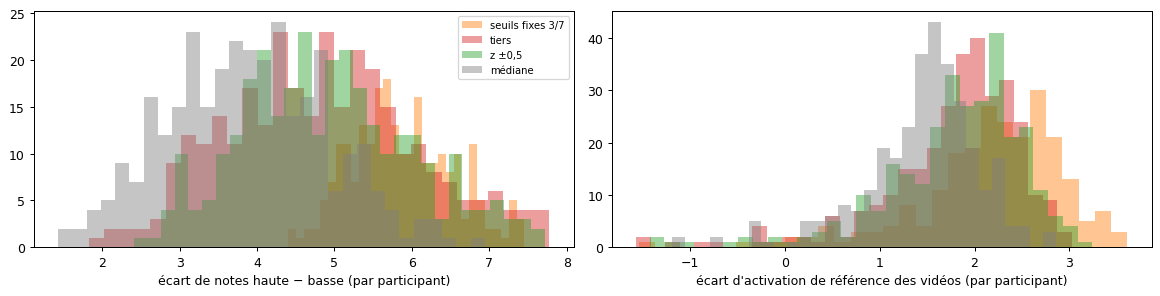

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for m, col in zip(METHODS, ["C1", "C3", "C2", "grey"]):
    p = per[m]
    axs[0].hist(p["note"]["haute"] - p["note"]["basse"], bins=30, alpha=.45, color=col, label=m)
    axs[1].hist(p["norme"]["haute"] - p["norme"]["basse"], bins=30, alpha=.45, color=col, label=m)
axs[0].set_xlabel("écart de notes haute − basse (par participant)"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("écart d'activation de référence des vidéos (par participant)")
plt.tight_layout(); plt.show()

**Lecture** :
- les **seuils fixes** donnent le plus fort contraste, mais font perdre environ un quart des participants
  et laissent des groupes plus petits ;
- la **médiane** garde tout le monde avec de grands groupes, mais mélange des vidéos proches du milieu de
  l'échelle : contraste nettement plus faible ;
- **tiers** et **z ±0,5** sont presque identiques : presque tous les participants gardés, ~33 vidéos
  par groupe, bon contraste, et les vidéos « hautes » sont aussi jugées plus activantes par les autres.

## 3. Définition retenue

**Tiers de chaque participant** (sur toutes ses vidéos notées, tous jours confondus) :
- « basse » = son tiers de vidéos les moins activantes, « haute » = son tiers le plus activant ;
- le tiers du milieu est laissé de côté (il rend les groupes plus contrastés) ;
- avec des ex æquo (notes entières), on choisit le seuil qui donne le groupe le plus proche d'un tiers ;
- participant **exclu** si ses notes ont un écart-type < 1 ou s'il a moins de 8 vidéos dans un groupe.

Préférée à z ±0,5 (résultats équivalents) parce qu'elle est plus simple à expliquer et ne suppose rien
sur la forme de la distribution des notes.

In [6]:
d = split_all(lab)
s = d.groupby("participant_id").agg(cohorte=("cohort", "first"), discriminant=("discriminant", "first"),
                                    seuil_basse=("seuil_basse", "first"), seuil_haute=("seuil_haute", "first"))
print(f"Participants gardés : {s.discriminant.sum()} / {len(s)}")
excl = s[~s.discriminant].join(u[["ecart_type", "n_videos"]])
print("Exclus :"); print(excl.round(2))
ecart = s.seuil_haute - s.seuil_basse
print(f"Écart entre les deux seuils : médiane {ecart.median():.1f} point ; < 1 point pour {(ecart < 1).sum()} participants")

Participants gardés : 308 / 317
Exclus :
                cohorte  discriminant  seuil_basse  seuil_haute  ecart_type  \
participant_id                                                                
P040                  1         False         5.00         7.00        0.80   
P211                  2         False         5.59         6.18        0.55   
P213                  2         False         5.06         6.04        0.94   
P218                  2         False         6.86         7.69        0.72   
P361                  5         False         2.95         7.54        3.14   
P367                  5         False         6.65         8.31        3.08   
P370                  5         False         2.26         7.13        2.72   
P375                  5         False         1.00         3.98        1.75   
P382                  5         False         1.00         5.11        2.94   

                n_videos  
participant_id            
P040                  88  
P211    

## 4. Utilisation (pour toute l'équipe)

```python
from arousal_split import load_ratings, split_all
lab = split_all(load_ratings())                       # une ligne par vidéo notée
lab = lab[lab.discriminant]                           # participants exploitables
hautes = lab[lab.cond == "haute"]; basses = lab[lab.cond == "basse"]
```
Colonnes ajoutées : `cond` (basse / moyenne / haute), `seuil_basse`, `seuil_haute`, `discriminant`.
Pour relier aux enregistrements : `participant_id`, `day`, `start_marker` (= `marker_id` du metadata).

`hep_utils.py` utilise déjà la même fonction (`tertile_cuts`) : l'analyse HEP de groupe suit donc
cette définition. Parmi ses 26 participants, voici ceux que cette définition exclurait :

In [7]:
hep_subj = ["P001", "P006", "P017", "P020", "P026", "P027", "P086", "P090", "P097", "P106", "P124", "P138", "P165",
            "P177", "P178", "P181", "P187", "P193", "P210", "P212", "P298", "P302", "P316", "P354", "P448", "P462"]
print([p for p in hep_subj if p in s.index and not s.loc[p, "discriminant"]] or "aucun")

aucun


## 5. Limites
- Les notes sont **subjectives** et relatives : « haute » veut dire « plus activante que ses autres
  vidéos pour cette personne », pas un niveau absolu d'activation.
- Pour une vingtaine de participants, les deux seuils sont à moins d'un point d'écart : le contraste
  haute / basse est faible chez eux.
- Les vidéos vues deux fois ne changent de groupe que rarement (cohérence ~94 %), mais elles ne
  concernent qu'une petite partie des participants.
- On n'utilise que `labels_train.csv` : les notes présentes dans les `metadata.json` pour des vidéos
  absentes de `labels_train` (probablement réservées à l'évaluation) ne sont jamais utilisées.